# **LAPORAN PANDAPOWER**

Nama: 1. Farrel Amaris Ipaenen (24/538573/SV/24512), 2. Miftahul Rizqi (24/538915/SV/24549)

Kelas: RE2A2

Dosen: Muhammad Rifqi Al Fauzan, S.Si., M.Si.

Asisten Dosen: 1. Wildy Zhalifunnas, 2.	Shiddiq Ahmad Fauzan



**Single Line Diagram (SLD) Sebelum**

SLD digunakan untuk memudahkan dalam mengamati line (jalur) antar bus pada khususnya sebelum dilakukan penambahan tie-line.

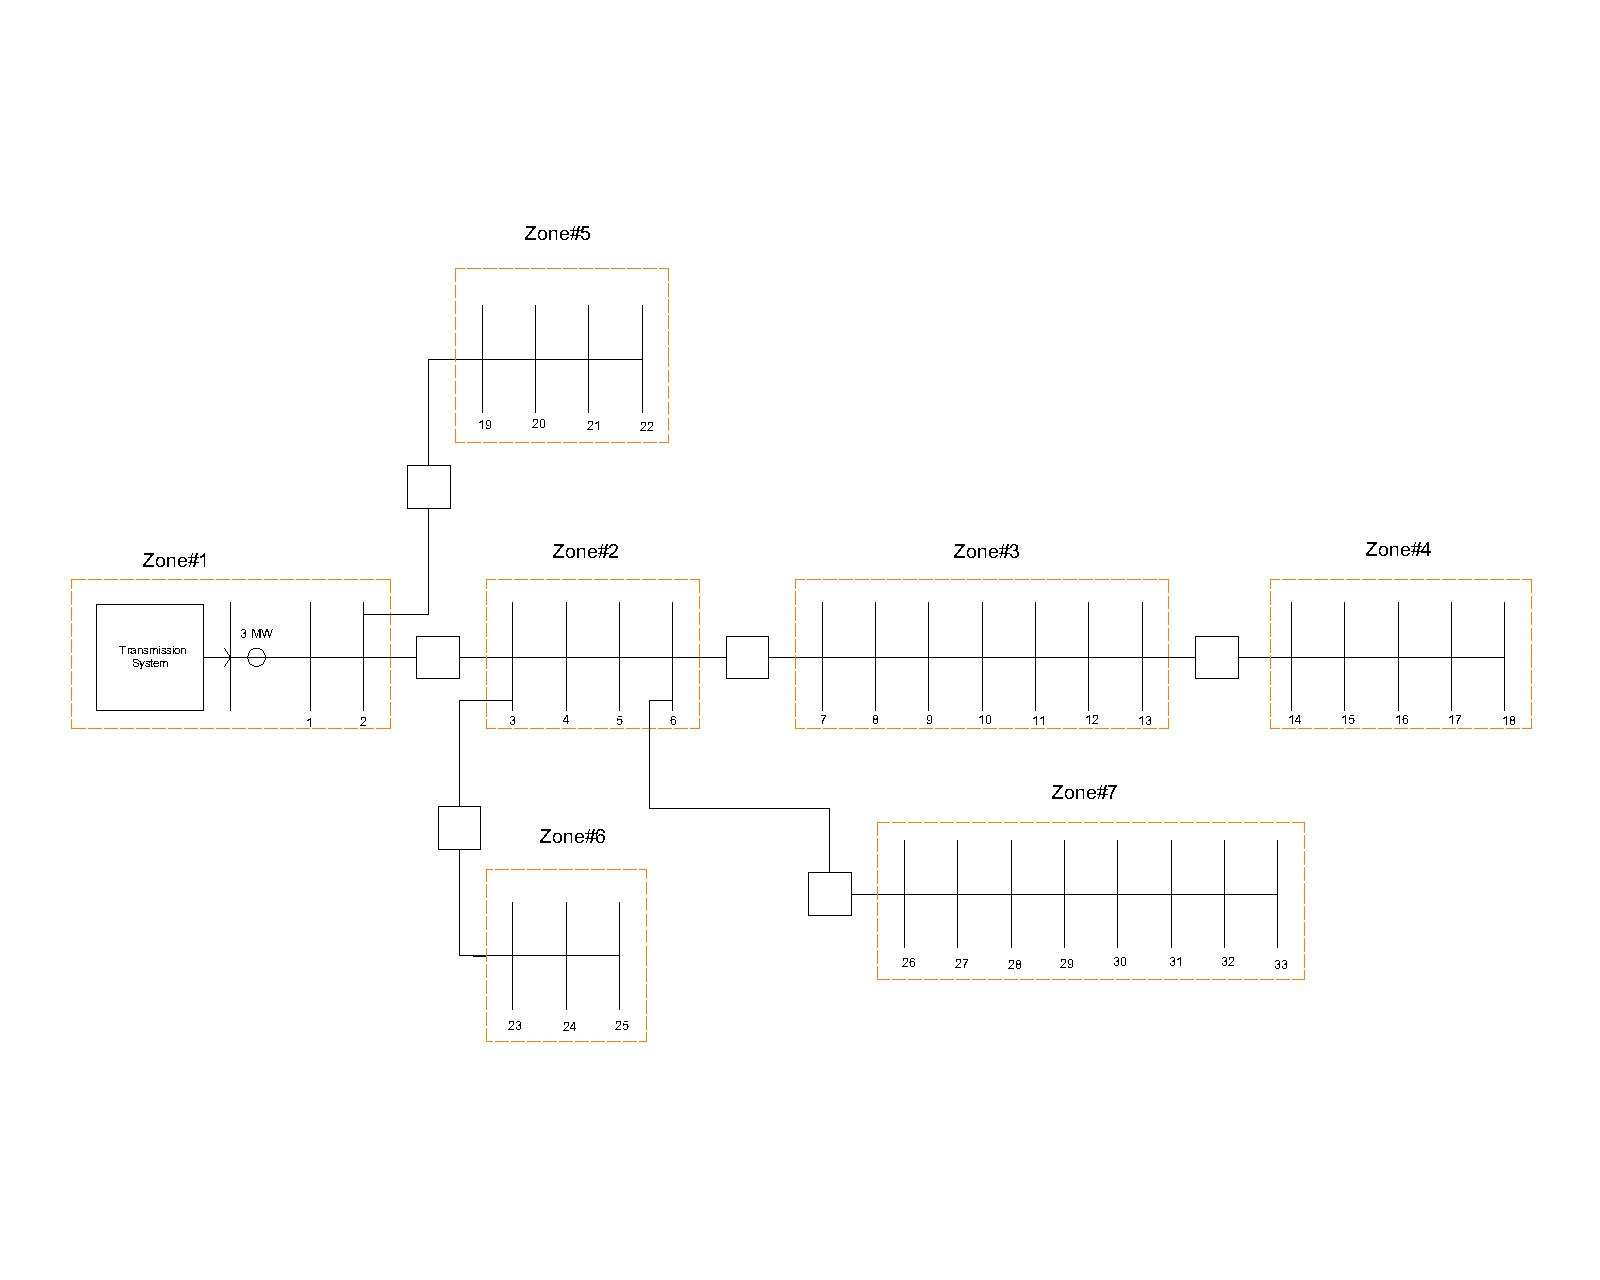

**Single Line Diagram Sesudah**

Sesudah tie-line ditambahkan untuk memperbaiki jaringan, SLD dapat memudahkan kita dalam melihat perubahan yang terjadi dalam bentuk gambar sehingga perubahan tersebut dapat tervisualisasi dengan baik dan jelas.

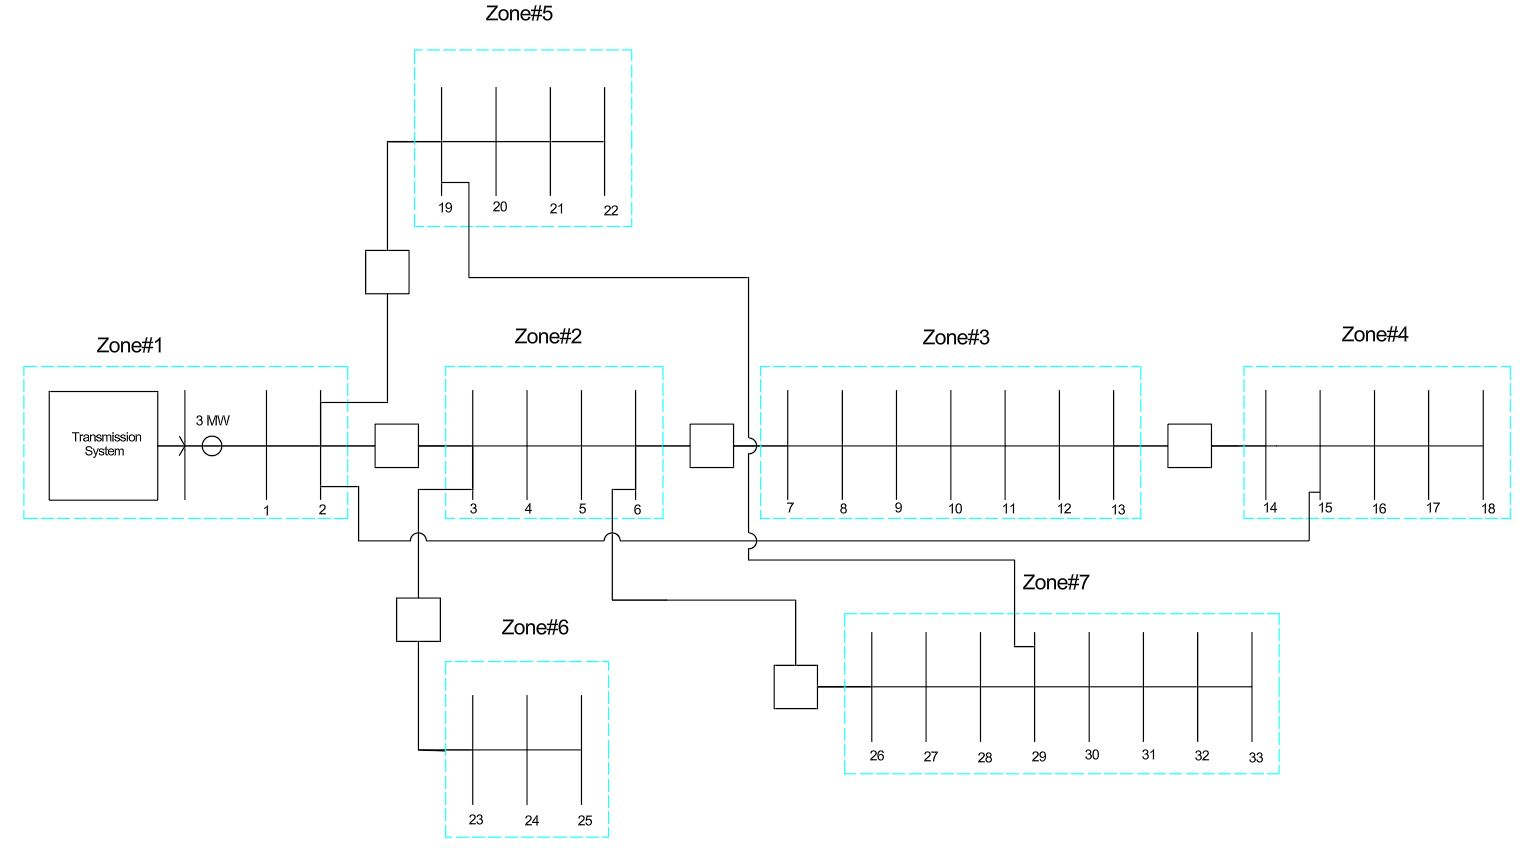


**Output**

Kode program menggunakan library matplotlib.pyplot untuk memplot dua profil tegangan yang berbeda: kondisi "Sebelum Optimasi" dan "Setelah Optimasi". Grafik ini dibuat dengan memplot nomor bus pada sumbu X dan nilai tegangan dalam per unit (p.u.) pada sumbu Y. Garis merah dengan marker lingkaran merepresentasikan profil tegangan sebelum optimasi, sementara garis biru menunjukkan profil tegangan setelah optimasi.

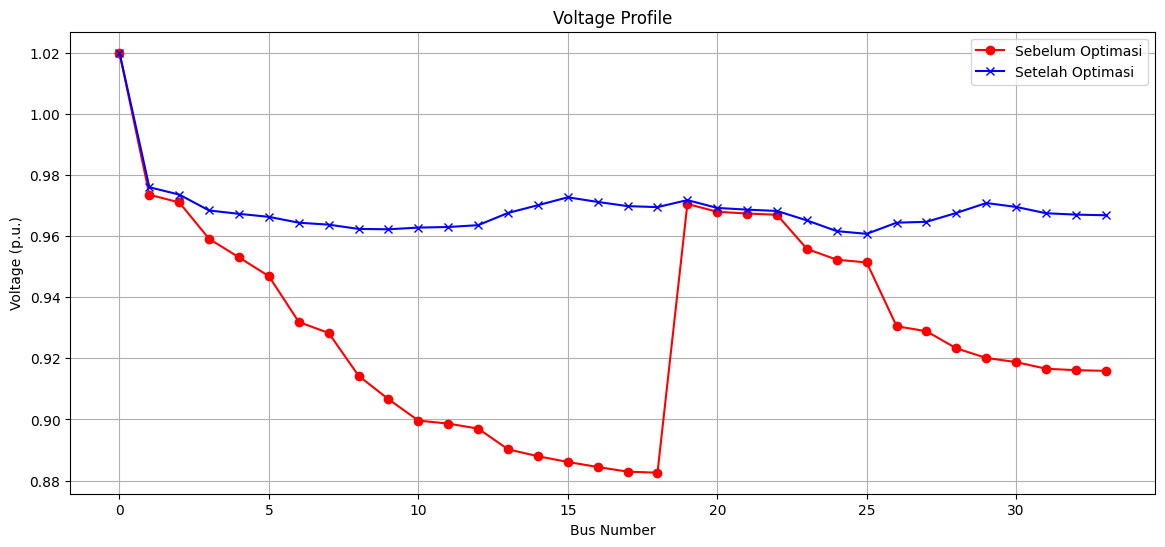

In [ ]:
plt.figure(figsize=(14, 6))
plt.plot(df_before['Bus'], df_before['Voltage (p.u.)'], label='Sebelum Optimasi', marker='o', color='red')
plt.plot(df_after['Bus'], df_after['Voltage (p.u.)'], label='Setelah Optimasi', marker='x', color='blue')
plt.xlabel('Bus Number')
plt.ylabel('Voltage (p.u.)')
plt.title('Voltage Profile')
plt.grid(True)
plt.legend()
plt.show()

# Install Pandapower

Proses instalasi Pandapower dijelaskan sebagai fondasi untuk menjalankan program. Ini dilakukan dengan menjalankan perintah !pip install pandapower dalam lingkungan pengembangan, memastikan semua dependensi yang diperlukan terpasang dengan benar.

In [ ]:
pip install pandapower[all]

# Import Library

Beberapa pustaka (libraries) Python telah diimpor untuk menunjang proses pemodelan, analisis, dan visualisasi data. Pustaka pertama yang digunakan adalah **pandapower**, yang diimpor dengan alias pp. pandapower dipilih sebagai alat utama untuk memodelkan dan menganalisis jaringan tenaga listrik yang ditinjau, karena kemampuannya dalam simulasi aliran daya dan berbagai studi grid lainnya. Selain itu, pustaka **matplotlib** juga diimpor. Matplotlib adalah pustaka penggambaran (plotting) yang komprehensif untuk Python. Pustaka ini menyediakan beragam alat untuk membuat visualisasi statis.

In [ ]:
import pandapower as pp
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Source Code

Bagian ini merupakan inti dari analisis jaringan tenaga listrik. Di sini, kita akan mendefinisikan atau memuat model jaringan listrik menggunakan pustaka pandapower. Pemodelan ini mencakup penentuan elemen-elemen jaringan seperti bus (titik sambung), saluran transmisi (lines), transformator (trafos), beban (loads), generator, dan komponen lainnya.

Setelah model jaringan berhasil dibuat, kita akan menjalankan simulasi aliran daya (runpp) menggunakan fungsi-fungsi yang disediakan oleh pandapower. Simulasi ini menghitung kondisi operasional jaringan, seperti distribusi tegangan di setiap bus dan aliran daya pada setiap komponen, berdasarkan konfigurasi dan beban yang diberikan.

**Sebelum Optimasi**

*Membuat Jaringan:*

Tahap awal adalah inisialisasi model jaringan tenaga listrik dasar yang diberi nama net 1. Ini menjadi fondasi struktural grid sebelum elemen-elemen fungsional ditambahkan.

In [ ]:
net1 = pp.create_empty_network()
bus0 = pp.create_bus(net1, vn_kv=132., name="Bus 0")
bus_dict = {}
for i in range(1, 34):
    label = f"Bus {i}"
    bus_dict[label] = pp.create_bus(net1, vn_kv=13.8, name=label)

*Membuat Beban per Bus:*

Selanjutnya, dilakukan pendefinisian dan penambahan nilai beban pada setiap titik hubung (bus) dalam jaringan net 1. Beban ini merepresentasikan kebutuhan konsumsi daya di berbagai lokasi sistem.

In [ ]:
pp.create_ext_grid(net1, bus=bus0, vm_pu=1.02, name="Grid Connection")
pp.create_load(net1, bus=bus_dict["Bus 1"], p_mw=0.053, q_mvar=0.053*0.618, name="Load 1")
pp.create_load(net1, bus=bus_dict["Bus 2"], p_mw=0.047, q_mvar=0.047*0.618, name="Load 2")
pp.create_load(net1, bus=bus_dict["Bus 3"], p_mw=0.124, q_mvar=0.124*0.618, name="Load 3")
pp.create_load(net1, bus=bus_dict["Bus 4"], p_mw=0.058, q_mvar=0.058*0.618, name="Load 4")
pp.create_load(net1, bus=bus_dict["Bus 5"], p_mw=0.069, q_mvar=0.069*0.618, name="Load 5")
pp.create_load(net1, bus=bus_dict["Bus 6"], p_mw=0.079, q_mvar=0.079*0.618, name="Load 6")
pp.create_load(net1, bus=bus_dict["Bus 7"], p_mw=0.112, q_mvar=0.112*0.618, name="Load 7")
pp.create_load(net1, bus=bus_dict["Bus 8"], p_mw=0.088, q_mvar=0.088*0.618, name="Load 8")
pp.create_load(net1, bus=bus_dict["Bus 9"], p_mw=0.083, q_mvar=0.083*0.618, name="Load 9")
pp.create_load(net1, bus=bus_dict["Bus 10"], p_mw=0.085, q_mvar=0.085*0.618, name="Load 10")
pp.create_load(net1, bus=bus_dict["Bus 11"], p_mw=0.094, q_mvar=0.094*0.618, name="Load 11")
pp.create_load(net1, bus=bus_dict["Bus 12"], p_mw=0.089, q_mvar=0.089*0.618, name="Load 12")
pp.create_load(net1, bus=bus_dict["Bus 13"], p_mw=0.134, q_mvar=0.134*0.618, name="Load 13")
pp.create_load(net1, bus=bus_dict["Bus 14"], p_mw=0.048, q_mvar=0.048*0.618, name="Load 14")
pp.create_load(net1, bus=bus_dict["Bus 15"], p_mw=0.084, q_mvar=0.084*0.618, name="Load 15")
pp.create_load(net1, bus=bus_dict["Bus 16"], p_mw=0.15, q_mvar=0.15*0.618, name="Load 16")
pp.create_load(net1, bus=bus_dict["Bus 17"], p_mw=0.053, q_mvar=0.053*0.618, name="Load 17")
pp.create_load(net1, bus=bus_dict["Bus 18"], p_mw=0.055, q_mvar=0.055*0.618, name="Load 18")
pp.create_load(net1, bus=bus_dict["Bus 19"], p_mw=0.158, q_mvar=0.158*0.618, name="Load 19")
pp.create_load(net1, bus=bus_dict["Bus 20"], p_mw=0.056, q_mvar=0.056*0.618, name="Load 20")
pp.create_load(net1, bus=bus_dict["Bus 21"], p_mw=0.084, q_mvar=0.084*0.618, name="Load 21")
pp.create_load(net1, bus=bus_dict["Bus 22"], p_mw=0.062, q_mvar=0.062*0.618, name="Load 22")
pp.create_load(net1, bus=bus_dict["Bus 23"], p_mw=0.450, q_mvar=0.450*0.618, name="Load 23")
pp.create_load(net1, bus=bus_dict["Bus 24"], p_mw=0.358, q_mvar=0.358*0.618, name="Load 24")
pp.create_load(net1, bus=bus_dict["Bus 25"], p_mw=0.122, q_mvar=0.122*0.618, name="Load 25")
pp.create_load(net1, bus=bus_dict["Bus 26"], p_mw=0.134, q_mvar=0.134*0.618, name="Load 26")
pp.create_load(net1, bus=bus_dict["Bus 27"], p_mw=0.178, q_mvar=0.178*0.618, name="Load 27")
pp.create_load(net1, bus=bus_dict["Bus 28"], p_mw=0.155, q_mvar=0.155*0.618, name="Load 28")
pp.create_load(net1, bus=bus_dict["Bus 29"], p_mw=0.089, q_mvar=0.089*0.618, name="Load 29")
pp.create_load(net1, bus=bus_dict["Bus 30"], p_mw=0.112, q_mvar=0.112*0.618, name="Load 30")
pp.create_load(net1, bus=bus_dict["Bus 31"], p_mw=0.087, q_mvar=0.087*0.618, name="Load 31")
pp.create_load(net1, bus=bus_dict["Bus 32"], p_mw=0.097, q_mvar=0.097*0.618, name="Load 32")
pp.create_load(net1, bus=bus_dict["Bus 33"], p_mw=0.058, q_mvar=0.058*0.618, name="Load 33")

np.int64(32)

*Membuat Transformator:*

Komponen transformator ditambahkan ke dalam model jaringan. Transformator ini berfungsi sebagai penghubung antar level tegangan dalam sistem.

In [ ]:
pp.create_transformer_from_parameters(
    net1,
    hv_bus=bus0,
    lv_bus=bus_dict["Bus 1"],
    sn_mva=6.0,
    vn_hv_kv=132.0,
    vn_lv_kv=13.8,
    vkr_percent=0.5,
    vk_percent=10.0,
    pfe_kw=10.0,
    i0_percent=0.2,
    shift_degree=0,
    vector_group="Yyn",
    vk0_percent=10.0,
    vkr0_percent=0.5,
    mag0_percent=100.0,
    mag0_rx=1.0,
    name="Trafo 5MVA 132/13.8kV",
    in_service=True
)

np.int64(0)

*Membuat Koneksi antar Bus:*

Tahap ini meliputi pembentukan koneksi fisik antar bus melalui pendefinisian dan penambahan saluran transmisi (lines). Saluran ini menetapkan jalur melalui mana daya mengalir.

In [ ]:
connections = [
    (1,2), (2,3), (3,4), (4,5), (5,6), (6,7), (7,8), (8,9), (9,10), (10,11), (11,12), (12,13), (13,14),
    (14,15), (15,16), (16,17), (17,18), (2,19), (19,20), (20,21), (21,22), (3,23), (23,24),
    (24,25), (6,26), (26,27), (27,28), (28,29), (29,30), (30,31), (31,32), (32,33)
]

pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 1"], to_bus=bus_dict["Bus 2"], length_km=1.0, r_ohm_per_km=0.0922, x_ohm_per_km=0.0477, c_nf_per_km=0, max_i_ka=0.5, name="Line 1-2")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 2"], to_bus=bus_dict["Bus 3"], length_km=1.0, r_ohm_per_km=0.4930, x_ohm_per_km=0.2511, c_nf_per_km=0, max_i_ka=0.5, name="Line 2-3")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 3"], to_bus=bus_dict["Bus 4"], length_km=1.0, r_ohm_per_km=0.3660, x_ohm_per_km=0.1864, c_nf_per_km=0, max_i_ka=0.5, name="Line 3-4")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 4"], to_bus=bus_dict["Bus 5"], length_km=1.0, r_ohm_per_km=0.3811, x_ohm_per_km=0.1941, c_nf_per_km=0, max_i_ka=0.5, name="Line 4-5")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 5"], to_bus=bus_dict["Bus 6"], length_km=1.0, r_ohm_per_km=0.8190, x_ohm_per_km=0.7070, c_nf_per_km=0, max_i_ka=0.5, name="Line 5-6")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 6"], to_bus=bus_dict["Bus 7"], length_km=1.0, r_ohm_per_km=0.1872, x_ohm_per_km=0.6188, c_nf_per_km=0, max_i_ka=0.5, name="Line 6-7")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 7"], to_bus=bus_dict["Bus 8"], length_km=1.0, r_ohm_per_km=1.7114, x_ohm_per_km=1.2351, c_nf_per_km=0, max_i_ka=0.5, name="Line 7-8")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 8"], to_bus=bus_dict["Bus 9"], length_km=1.0, r_ohm_per_km=1.0300, x_ohm_per_km=0.7400, c_nf_per_km=0, max_i_ka=0.5, name="Line 8-9")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 9"], to_bus=bus_dict["Bus 10"], length_km=1.0, r_ohm_per_km=1.0400, x_ohm_per_km=0.7400, c_nf_per_km=0, max_i_ka=0.5, name="Line 9-10")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 10"], to_bus=bus_dict["Bus 11"], length_km=1.0, r_ohm_per_km=0.1966, x_ohm_per_km=0.0650, c_nf_per_km=0, max_i_ka=0.5, name="Line 10-11")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 11"], to_bus=bus_dict["Bus 12"], length_km=1.0, r_ohm_per_km=0.3744, x_ohm_per_km=0.1238, c_nf_per_km=0, max_i_ka=0.5, name="Line 11-12")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 12"], to_bus=bus_dict["Bus 13"], length_km=1.0, r_ohm_per_km=1.4680, x_ohm_per_km=1.1550, c_nf_per_km=0, max_i_ka=0.5, name="Line 12-13")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 13"], to_bus=bus_dict["Bus 14"], length_km=1.0, r_ohm_per_km=0.5416, x_ohm_per_km=0.7129, c_nf_per_km=0, max_i_ka=0.5, name="Line 13-14")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 14"], to_bus=bus_dict["Bus 15"], length_km=1.0, r_ohm_per_km=0.5910, x_ohm_per_km=0.5260, c_nf_per_km=0, max_i_ka=0.5, name="Line 14-15")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 15"], to_bus=bus_dict["Bus 16"], length_km=1.0, r_ohm_per_km=0.7463, x_ohm_per_km=0.5450, c_nf_per_km=0, max_i_ka=0.5, name="Line 15-16")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 16"], to_bus=bus_dict["Bus 17"], length_km=1.0, r_ohm_per_km=1.2890, x_ohm_per_km=1.7210, c_nf_per_km=0, max_i_ka=0.5, name="Line 16-17")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 17"], to_bus=bus_dict["Bus 18"], length_km=1.0, r_ohm_per_km=0.7320, x_ohm_per_km=0.5740, c_nf_per_km=0, max_i_ka=0.5, name="Line 17-18")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 2"], to_bus=bus_dict["Bus 19"], length_km=1.0, r_ohm_per_km=0.1640, x_ohm_per_km=0.1565, c_nf_per_km=0, max_i_ka=0.5, name="Line 2-19")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 19"], to_bus=bus_dict["Bus 20"], length_km=1.0, r_ohm_per_km=1.5042, x_ohm_per_km=1.3554, c_nf_per_km=0, max_i_ka=0.5, name="Line 19-20")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 20"], to_bus=bus_dict["Bus 21"], length_km=1.0, r_ohm_per_km=0.4095, x_ohm_per_km=0.4784, c_nf_per_km=0, max_i_ka=0.5, name="Line 20-21")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 21"], to_bus=bus_dict["Bus 22"], length_km=1.0, r_ohm_per_km=0.7089, x_ohm_per_km=0.9373, c_nf_per_km=0, max_i_ka=0.5, name="Line 21-22")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 3"], to_bus=bus_dict["Bus 23"], length_km=1.0, r_ohm_per_km=0.4512, x_ohm_per_km=0.3083, c_nf_per_km=0, max_i_ka=0.5, name="Line 3-23")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 23"], to_bus=bus_dict["Bus 24"], length_km=1.0, r_ohm_per_km=0.8980, x_ohm_per_km=0.7091, c_nf_per_km=0, max_i_ka=0.5, name="Line 23-24")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 24"], to_bus=bus_dict["Bus 25"], length_km=1.0, r_ohm_per_km=0.8960, x_ohm_per_km=0.7011, c_nf_per_km=0, max_i_ka=0.5, name="Line 24-25")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 6"], to_bus=bus_dict["Bus 26"], length_km=1.0, r_ohm_per_km=0.2030, x_ohm_per_km=0.1034, c_nf_per_km=0, max_i_ka=0.5, name="Line 6-26")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 26"], to_bus=bus_dict["Bus 27"], length_km=1.0, r_ohm_per_km=0.2842, x_ohm_per_km=0.1447, c_nf_per_km=0, max_i_ka=0.5, name="Line 26-27")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 27"], to_bus=bus_dict["Bus 28"], length_km=1.0, r_ohm_per_km=1.0590, x_ohm_per_km=0.9337, c_nf_per_km=0, max_i_ka=0.5, name="Line 27-28")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 28"], to_bus=bus_dict["Bus 29"], length_km=1.0, r_ohm_per_km=0.8042, x_ohm_per_km=0.7006, c_nf_per_km=0, max_i_ka=0.5, name="Line 28-29")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 29"], to_bus=bus_dict["Bus 30"], length_km=1.0, r_ohm_per_km=0.5075, x_ohm_per_km=0.2585, c_nf_per_km=0, max_i_ka=0.5, name="Line 29-30")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 30"], to_bus=bus_dict["Bus 31"], length_km=1.0, r_ohm_per_km=0.9744, x_ohm_per_km=0.9630, c_nf_per_km=0, max_i_ka=0.5, name="Line 30-31")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 31"], to_bus=bus_dict["Bus 32"], length_km=1.0, r_ohm_per_km=0.3105, x_ohm_per_km=0.3619, c_nf_per_km=0, max_i_ka=0.5, name="Line 31-32")
pp.create_line_from_parameters(net1, from_bus=bus_dict["Bus 32"], to_bus=bus_dict["Bus 33"], length_km=1.0, r_ohm_per_km=0.3410, x_ohm_per_km=0.5302, c_nf_per_km=0, max_i_ka=0.5, name="Line 32-33")


np.int64(31)

*Menjalankan Program untuk Aliran Daya Jaringan:*

Setelah struktur jaringan lengkap, simulasi aliran daya (power flow) dieksekusi pada model net 1 menggunakan fungsi runpp dari pustaka pandapower. Hasil simulasi ini memberikan gambaran kondisi operasional jaringan dalam konfigurasi awal.

In [ ]:
pp.runpp(net1)
voltages_before = net1.res_bus.vm_pu.values
df_before = pd.DataFrame({
    'Bus': range(0, len(net1.bus)),
    'Voltage (p.u.)': voltages_before
})

**Setelah Optimasi**

*Membuat Jaringan:*

Inisialisasi model jaringan tenaga listrik kedua dilakukan, dinamai net 2. Model ini akan merepresentasikan jaringan setelah modifikasi atau optimasi.

In [ ]:
net2 = pp.create_empty_network()
bus0a = pp.create_bus(net2, vn_kv=132., name ="Bus 0")
bus_dict2 = {}
for i in range(1, 34):
    label = f"Bus {i}"
    bus_dict2[label] = pp.create_bus(net2, vn_kv=13.8, name=label)

*Membuat Beban per Bus:*

Nilai beban pada setiap bus didefinisikan dan ditambahkan kembali ke dalam jaringan net 2. Diasumsikan nilai beban ini sama dengan kondisi "Sebelum Optimasi".

In [ ]:
pp.create_ext_grid(net2, bus=bus0, vm_pu= 1.02, name="Grid Connection")
pp.create_load(net2, bus=bus_dict2["Bus 1"], p_mw=0.053, q_mvar=0.053*0.618, name="Load 1")
pp.create_load(net2, bus=bus_dict2["Bus 2"], p_mw=0.047, q_mvar=0.047*0.618, name="Load 2")
pp.create_load(net2, bus=bus_dict2["Bus 3"], p_mw=0.124, q_mvar=0.124*0.618, name="Load 3")
pp.create_load(net2, bus=bus_dict2["Bus 4"], p_mw=0.058, q_mvar=0.058*0.618, name="Load 4")
pp.create_load(net2, bus=bus_dict2["Bus 5"], p_mw=0.069, q_mvar=0.069*0.618, name="Load 5")
pp.create_load(net2, bus=bus_dict2["Bus 6"], p_mw=0.079, q_mvar=0.079*0.618, name="Load 6")
pp.create_load(net2, bus=bus_dict2["Bus 7"], p_mw=0.112, q_mvar=0.112*0.618, name="Load 7")
pp.create_load(net2, bus=bus_dict2["Bus 8"], p_mw=0.088, q_mvar=0.088*0.618, name="Load 8")
pp.create_load(net2, bus=bus_dict2["Bus 9"], p_mw=0.083, q_mvar=0.083*0.618, name="Load 9")
pp.create_load(net2, bus=bus_dict2["Bus 10"], p_mw=0.085, q_mvar=0.085*0.618, name="Load 10")
pp.create_load(net2, bus=bus_dict2["Bus 11"], p_mw=0.094, q_mvar=0.094*0.618, name="Load 11")
pp.create_load(net2, bus=bus_dict2["Bus 12"], p_mw=0.089, q_mvar=0.089*0.618, name="Load 12")
pp.create_load(net2, bus=bus_dict2["Bus 13"], p_mw=0.134, q_mvar=0.134*0.618, name="Load 13")
pp.create_load(net2, bus=bus_dict2["Bus 14"], p_mw=0.048, q_mvar=0.048*0.618, name="Load 14")
pp.create_load(net2, bus=bus_dict2["Bus 15"], p_mw=0.084, q_mvar=0.084*0.618, name="Load 15")
pp.create_load(net2, bus=bus_dict2["Bus 16"], p_mw=0.15, q_mvar=0.15*0.618, name="Load 16")
pp.create_load(net2, bus=bus_dict2["Bus 17"], p_mw=0.053, q_mvar=0.053*0.618, name="Load 17")
pp.create_load(net2, bus=bus_dict2["Bus 18"], p_mw=0.055, q_mvar=0.055*0.618, name="Load 18")
pp.create_load(net2, bus=bus_dict2["Bus 19"], p_mw=0.158, q_mvar=0.158*0.618, name="Load 19")
pp.create_load(net2, bus=bus_dict2["Bus 20"], p_mw=0.056, q_mvar=0.056*0.618, name="Load 20")
pp.create_load(net2, bus=bus_dict2["Bus 21"], p_mw=0.084, q_mvar=0.084*0.618, name="Load 21")
pp.create_load(net2, bus=bus_dict2["Bus 22"], p_mw=0.062, q_mvar=0.062*0.618, name="Load 22")
pp.create_load(net2, bus=bus_dict2["Bus 23"], p_mw=0.450, q_mvar=0.450*0.618, name="Load 23")
pp.create_load(net2, bus=bus_dict2["Bus 24"], p_mw=0.358, q_mvar=0.358*0.618, name="Load 24")
pp.create_load(net2, bus=bus_dict2["Bus 25"], p_mw=0.122, q_mvar=0.122*0.618, name="Load 25")
pp.create_load(net2, bus=bus_dict2["Bus 26"], p_mw=0.134, q_mvar=0.134*0.618, name="Load 26")
pp.create_load(net2, bus=bus_dict2["Bus 27"], p_mw=0.178, q_mvar=0.178*0.618, name="Load 27")
pp.create_load(net2, bus=bus_dict2["Bus 28"], p_mw=0.155, q_mvar=0.155*0.618, name="Load 28")
pp.create_load(net2, bus=bus_dict2["Bus 29"], p_mw=0.089, q_mvar=0.089*0.618, name="Load 29")
pp.create_load(net2, bus=bus_dict2["Bus 30"], p_mw=0.112, q_mvar=0.112*0.618, name="Load 30")
pp.create_load(net2, bus=bus_dict2["Bus 31"], p_mw=0.087, q_mvar=0.087*0.618, name="Load 31")
pp.create_load(net2, bus=bus_dict2["Bus 32"], p_mw=0.097, q_mvar=0.097*0.618, name="Load 32")
pp.create_load(net2, bus=bus_dict2["Bus 33"], p_mw=0.058, q_mvar=0.058*0.618, name="Load 33")

np.int64(32)

*Membuat Transformator:*

Komponen transformator ditambahkan ke dalam model jaringan net 2, serupa dengan tahap sebelumnya.

In [ ]:
pp.create_transformer_from_parameters(
    net2,
    hv_bus=bus0a,
    lv_bus=bus_dict2["Bus 1"],
    sn_mva=6.0,
    vn_hv_kv=132.0,
    vn_lv_kv=13.8,
    vkr_percent=0.5,
    vk_percent=10.0,
    pfe_kw=10.0,
    i0_percent=0.2,
    shift_degree=0,
    vector_group="Yyn",
    vk0_percent=10.0,
    vkr0_percent=0.5,
    mag0_percent=100.0,
    mag0_rx=1.0,
    name="Trafo 5MVA 132/13.8kV",
    in_service=True
)

np.int64(0)

*Membuat Koneksi antar Bus:*

Pada tahap ini, koneksi saluran transmisi antar bus yang ada dibuat kembali, dan secara krusial, ditambahkan tie-line baru. Penambahan tie-line ini merupakan bagian dari upaya optimasi untuk meningkatkan interkoneksi jaringan.

In [ ]:
connections = [
    (1,2), (2,3), (3,4), (4,5), (5,6), (6,7), (7,8), (8,9), (9,10), (10,11), (11,12), (12,13), (13,14),
    (14,15), (15,16), (16,17), (17,18), (2,19), (19,20), (20,21), (21,22), (3,23), (23,24),
    (24,25), (6,26), (26,27), (27,28), (28,29), (29,30), (30,31), (31,32), (32,33), (2,15), (19,29)
]

pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 1"], to_bus=bus_dict2["Bus 2"], length_km=1.0, r_ohm_per_km=0.0922, x_ohm_per_km=0.0477, c_nf_per_km=0, max_i_ka=0.5, name="Line 1-2")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 2"], to_bus=bus_dict2["Bus 3"], length_km=1.0, r_ohm_per_km=0.4930, x_ohm_per_km=0.2511, c_nf_per_km=0, max_i_ka=0.5, name="Line 2-3")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 3"], to_bus=bus_dict2["Bus 4"], length_km=1.0, r_ohm_per_km=0.3660, x_ohm_per_km=0.1864, c_nf_per_km=0, max_i_ka=0.5, name="Line 3-4")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 4"], to_bus=bus_dict2["Bus 5"], length_km=1.0, r_ohm_per_km=0.3811, x_ohm_per_km=0.1941, c_nf_per_km=0, max_i_ka=0.5, name="Line 4-5")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 5"], to_bus=bus_dict2["Bus 6"], length_km=1.0, r_ohm_per_km=0.8190, x_ohm_per_km=0.7070, c_nf_per_km=0, max_i_ka=0.5, name="Line 5-6")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 6"], to_bus=bus_dict2["Bus 7"], length_km=1.0, r_ohm_per_km=0.1872, x_ohm_per_km=0.6188, c_nf_per_km=0, max_i_ka=0.5, name="Line 6-7")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 7"], to_bus=bus_dict2["Bus 8"], length_km=1.0, r_ohm_per_km=1.7114, x_ohm_per_km=1.2351, c_nf_per_km=0, max_i_ka=0.5, name="Line 7-8")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 8"], to_bus=bus_dict2["Bus 9"], length_km=1.0, r_ohm_per_km=1.0300, x_ohm_per_km=0.7400, c_nf_per_km=0, max_i_ka=0.5, name="Line 8-9")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 9"], to_bus=bus_dict2["Bus 10"], length_km=1.0, r_ohm_per_km=1.0400, x_ohm_per_km=0.7400, c_nf_per_km=0, max_i_ka=0.5, name="Line 9-10")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 10"], to_bus=bus_dict2["Bus 11"], length_km=1.0, r_ohm_per_km=0.1966, x_ohm_per_km=0.0650, c_nf_per_km=0, max_i_ka=0.5, name="Line 10-11")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 11"], to_bus=bus_dict2["Bus 12"], length_km=1.0, r_ohm_per_km=0.3744, x_ohm_per_km=0.1238, c_nf_per_km=0, max_i_ka=0.5, name="Line 11-12")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 12"], to_bus=bus_dict2["Bus 13"], length_km=1.0, r_ohm_per_km=1.4680, x_ohm_per_km=1.1550, c_nf_per_km=0, max_i_ka=0.5, name="Line 12-13")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 13"], to_bus=bus_dict2["Bus 14"], length_km=1.0, r_ohm_per_km=0.5416, x_ohm_per_km=0.7129, c_nf_per_km=0, max_i_ka=0.5, name="Line 13-14")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 14"], to_bus=bus_dict2["Bus 15"], length_km=1.0, r_ohm_per_km=0.5910, x_ohm_per_km=0.5260, c_nf_per_km=0, max_i_ka=0.5, name="Line 14-15")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 15"], to_bus=bus_dict2["Bus 16"], length_km=1.0, r_ohm_per_km=0.7463, x_ohm_per_km=0.5450, c_nf_per_km=0, max_i_ka=0.5, name="Line 15-16")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 16"], to_bus=bus_dict2["Bus 17"], length_km=1.0, r_ohm_per_km=1.2890, x_ohm_per_km=1.7210, c_nf_per_km=0, max_i_ka=0.5, name="Line 16-17")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 17"], to_bus=bus_dict2["Bus 18"], length_km=1.0, r_ohm_per_km=0.7320, x_ohm_per_km=0.5740, c_nf_per_km=0, max_i_ka=0.5, name="Line 17-18")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 2"], to_bus=bus_dict2["Bus 19"], length_km=1.0, r_ohm_per_km=0.1640, x_ohm_per_km=0.1565, c_nf_per_km=0, max_i_ka=0.5, name="Line 2-19")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 19"], to_bus=bus_dict2["Bus 20"], length_km=1.0, r_ohm_per_km=1.5042, x_ohm_per_km=1.3554, c_nf_per_km=0, max_i_ka=0.5, name="Line 19-20")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 20"], to_bus=bus_dict2["Bus 21"], length_km=1.0, r_ohm_per_km=0.4095, x_ohm_per_km=0.4784, c_nf_per_km=0, max_i_ka=0.5, name="Line 20-21")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 21"], to_bus=bus_dict2["Bus 22"], length_km=1.0, r_ohm_per_km=0.7089, x_ohm_per_km=0.9373, c_nf_per_km=0, max_i_ka=0.5, name="Line 21-22")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 3"], to_bus=bus_dict2["Bus 23"], length_km=1.0, r_ohm_per_km=0.4512, x_ohm_per_km=0.3083, c_nf_per_km=0, max_i_ka=0.5, name="Line 3-23")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 23"], to_bus=bus_dict2["Bus 24"], length_km=1.0, r_ohm_per_km=0.8980, x_ohm_per_km=0.7091, c_nf_per_km=0, max_i_ka=0.5, name="Line 23-24")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 24"], to_bus=bus_dict2["Bus 25"], length_km=1.0, r_ohm_per_km=0.8960, x_ohm_per_km=0.7011, c_nf_per_km=0, max_i_ka=0.5, name="Line 24-25")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 6"], to_bus=bus_dict2["Bus 26"], length_km=1.0, r_ohm_per_km=0.2030, x_ohm_per_km=0.1034, c_nf_per_km=0, max_i_ka=0.5, name="Line 6-26")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 26"], to_bus=bus_dict2["Bus 27"], length_km=1.0, r_ohm_per_km=0.2842, x_ohm_per_km=0.1447, c_nf_per_km=0, max_i_ka=0.5, name="Line 26-27")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 27"], to_bus=bus_dict2["Bus 28"], length_km=1.0, r_ohm_per_km=1.0590, x_ohm_per_km=0.9337, c_nf_per_km=0, max_i_ka=0.5, name="Line 27-28")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 28"], to_bus=bus_dict2["Bus 29"], length_km=1.0, r_ohm_per_km=0.8042, x_ohm_per_km=0.7006, c_nf_per_km=0, max_i_ka=0.5, name="Line 28-29")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 29"], to_bus=bus_dict2["Bus 30"], length_km=1.0, r_ohm_per_km=0.5075, x_ohm_per_km=0.2585, c_nf_per_km=0, max_i_ka=0.5, name="Line 29-30")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 30"], to_bus=bus_dict2["Bus 31"], length_km=1.0, r_ohm_per_km=0.9744, x_ohm_per_km=0.9630, c_nf_per_km=0, max_i_ka=0.5, name="Line 30-31")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 31"], to_bus=bus_dict2["Bus 32"], length_km=1.0, r_ohm_per_km=0.3105, x_ohm_per_km=0.3619, c_nf_per_km=0, max_i_ka=0.5, name="Line 31-32")
pp.create_line_from_parameters(net2, from_bus=bus_dict2["Bus 32"], to_bus=bus_dict2["Bus 33"], length_km=1.0, r_ohm_per_km=0.3410, x_ohm_per_km=0.5302, c_nf_per_km=0, max_i_ka=0.5, name="Line 32-33")

pp.create_line(net2, from_bus=bus_dict2["Bus 2"], to_bus=bus_dict2["Bus 15"], length_km=1.0, std_type="NA2XS2Y 1x240 RM/25 12/20 kV", name="line 33")
pp.create_line(net2, from_bus=bus_dict2["Bus 19"], to_bus=bus_dict2["Bus 29"], length_km=1.0, std_type="NA2XS2Y 1x240 RM/25 12/20 kV", name="line 34")

np.int64(33)

*Menjalankan Program untuk Aliran Daya Jaringan:*

Simulasi aliran daya kembali dijalankan pada model jaringan yang telah dimodifikasi, yaitu net 2, menggunakan fungsi runpp. Hasil simulasi ini akan menunjukkan kondisi operasional jaringan setelah penambahan tie-line dan optimasi terkait lainnya, memungkinkan perbandingan dengan kondisi awal.

In [ ]:
pp.runpp(net2)
voltages_after = net2.res_bus.vm_pu.values
df_after = pd.DataFrame({
    'Bus': range(0, len(net2.bus)),
    'Voltage (p.u.)': voltages_after

})

# Visualisasi Data menggunakan Matplotlib

Untuk memahami hasil simulasi dan struktur jaringan, visualisasi memegang peranan penting. Pustaka **matplotlib** akan digunakan untuk menghasilkan representasi grafis dari jaringan dan hasil simulasi yang memvisualisasikan data hasil simulasi seperti profil tegangan, atau perbedaan nilai sebelum dan sesudah optimasi. Visualisasi ini membantu dalam identifikasi potensi masalah, analisis performa jaringan, dan validasi hasil simulasi.

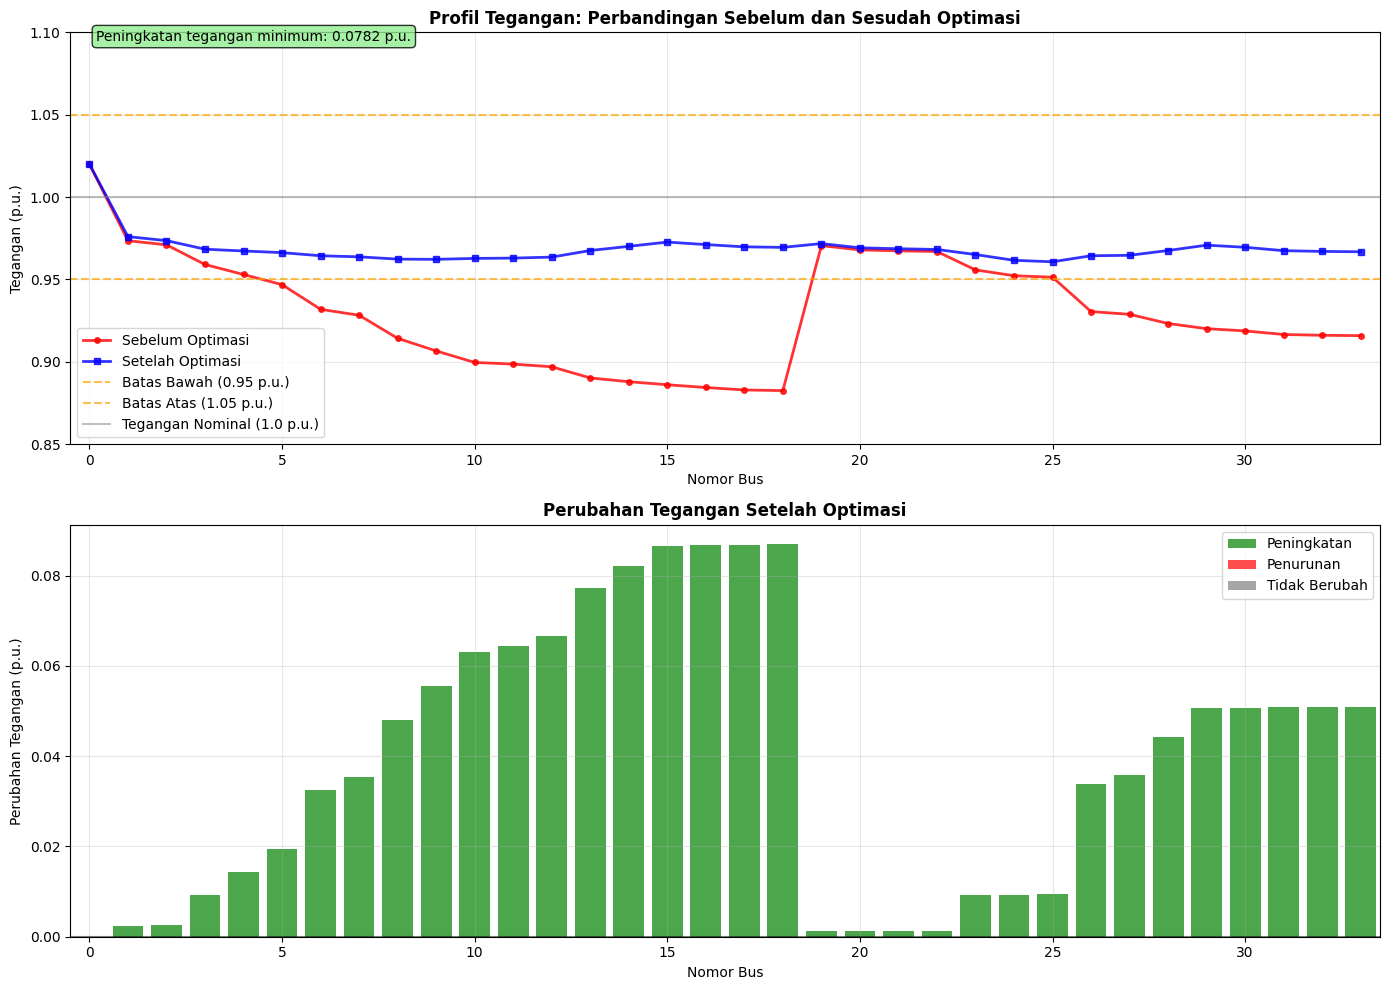

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Plot 1: Perbandingan Profil Tegangan
ax1.plot(df_before['Bus'], df_before['Voltage (p.u.)'],
        label='Sebelum Optimasi', marker='o', color='red',
        linewidth=2, markersize=4, alpha=0.8)
ax1.plot(df_after['Bus'], df_after['Voltage (p.u.)'],
        label='Setelah Optimasi', marker='s', color='blue',
        linewidth=2, markersize=4, alpha=0.8)

ax1.axhline(y=0.95, color='orange', linestyle='--', alpha=0.7,
            label='Batas Bawah (0.95 p.u.)')
ax1.axhline(y=1.05, color='orange', linestyle='--', alpha=0.7,
            label='Batas Atas (1.05 p.u.)')
ax1.axhline(y=1.0, color='gray', linestyle='-', alpha=0.5,
            label='Tegangan Nominal (1.0 p.u.)')

ax1.set_xlabel('Nomor Bus')
ax1.set_ylabel('Tegangan (p.u.)')
ax1.set_title('Profil Tegangan: Perbandingan Sebelum dan Sesudah Optimasi',
            fontweight='bold', fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend()
ax1.set_xlim(-0.5, len(df_before) - 0.5)
ax1.set_ylim(0.85, 1.1)

improvement = df_after['Voltage (p.u.)'].min() - df_before['Voltage (p.u.)'].min()
ax1.text(0.02, 0.98, f'Peningkatan tegangan minimum: {improvement:.4f} p.u.',
        transform=ax1.transAxes, fontsize=10,
        bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.8))

# Plot 2: Perbedaan Tegangan (Improvement)
voltage_diff = df_after['Voltage (p.u.)'] - df_before['Voltage (p.u.)']
colors = ['green' if x > 0 else 'red' if x < 0 else 'gray' for x in voltage_diff]

bars = ax2.bar(df_before['Bus'], voltage_diff, color=colors, alpha=0.7, width=0.8)
ax2.axhline(y=0, color='black', linestyle='-', alpha=0.5)
ax2.set_xlabel('Nomor Bus')
ax2.set_ylabel('Perubahan Tegangan (p.u.)')
ax2.set_title('Perubahan Tegangan Setelah Optimasi', fontweight='bold')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(-0.5, len(df_before) - 0.5)

# Legend untuk bar chart
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='green', alpha=0.7, label='Peningkatan'),
                  Patch(facecolor='red', alpha=0.7, label='Penurunan'),
                  Patch(facecolor='gray', alpha=0.7, label='Tidak Berubah')]
ax2.legend(handles=legend_elements)

plt.tight_layout()
plt.show()

# Check Parameter

Check parameter bertujuan untuk verifikasi dan validasi nilai-nilai input atau konfigurasi yang telah digunakan dalam suatu fungsi, metode, atau model dan memastikan bahwa parameter yang diberikan berada dalam rentang yang valid, memiliki tipe data yang benar, dan sesuai dengan persyaratan yang ditentukan oleh fungsi atau proses yang dijalankan.

**NET 1**

In [ ]:
net1.bus

,name,vn_kv,type,zone,in_service,geo
0,Bus 0,132.0,b,None,True,None
1,Bus 1,13.8,b,None,True,None
2,Bus 2,13.8,b,None,True,None
3,Bus 3,13.8,b,None,True,None
4,Bus 4,13.8,b,None,True,None
5,Bus 5,13.8,b,None,True,None
6,Bus 6,13.8,b,None,True,None
7,Bus 7,13.8,b,None,True,None
8,Bus 8,13.8,b,None,True,None
9,Bus 9,13.8,b,None,True,None


In [ ]:
net1.line

,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,g_us_per_km,max_i_ka,df,parallel,type,in_service,geo
0,Line 1-2,None,1,2,1.0,0.0922,0.0477,0.0,0.0,0.5,1.0,1,None,True,None
1,Line 2-3,None,2,3,1.0,0.4930,0.2511,0.0,0.0,0.5,1.0,1,None,True,None
2,Line 3-4,None,3,4,1.0,0.3660,0.1864,0.0,0.0,0.5,1.0,1,None,True,None
3,Line 4-5,None,4,5,1.0,0.3811,0.1941,0.0,0.0,0.5,1.0,1,None,True,None
4,Line 5-6,None,5,6,1.0,0.8190,0.7070,0.0,0.0,0.5,1.0,1,None,True,None
5,Line 6-7,None,6,7,1.0,0.1872,0.6188,0.0,0.0,0.5,1.0,1,None,True,None
6,Line 7-8,None,7,8,1.0,1.7114,1.2351,0.0,0.0,0.5,1.0,1,None,True,None
7,Line 8-9,None,8,9,1.0,1.0300,0.7400,0.0,0.0,0.5,1.0,1,None,True,None
8,Line 9-10,None,9,10,1.0,1.0400,0.7400,0.0,0.0,0.5,1.0,1,None,True,None
9,Line 10-11,None,10,11,1.0,0.1966,0.0650,0.0,0.0,0.5,1.0,1,None,True,None


In [ ]:
net1.trafo

,name,std_type,hv_bus,lv_bus,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,...,id_characteristic_table,tap_dependency_table,parallel,df,in_service,vk0_percent,vkr0_percent,mag0_percent,mag0_rx,vector_group
0,Trafo 5MVA 132/13.8kV,None,0,1,6.0,132.0,13.8,10.0,0.5,10.0,...,<NA>,False,1,1.0,True,10.0,0.5,100.0,1.0,Yyn


In [ ]:
net1.load

,name,bus,p_mw,q_mvar,const_z_percent,const_i_percent,sn_mva,scaling,in_service,type
0,Load 1,1,0.053,0.032754,0.0,0.0,NaN,1.0,True,wye
1,Load 2,2,0.047,0.029046,0.0,0.0,NaN,1.0,True,wye
2,Load 3,3,0.124,0.076632,0.0,0.0,NaN,1.0,True,wye
3,Load 4,4,0.058,0.035844,0.0,0.0,NaN,1.0,True,wye
4,Load 5,5,0.069,0.042642,0.0,0.0,NaN,1.0,True,wye
5,Load 6,6,0.079,0.048822,0.0,0.0,NaN,1.0,True,wye
6,Load 7,7,0.112,0.069216,0.0,0.0,NaN,1.0,True,wye
7,Load 8,8,0.088,0.054384,0.0,0.0,NaN,1.0,True,wye
8,Load 9,9,0.083,0.051294,0.0,0.0,NaN,1.0,True,wye
9,Load 10,10,0.085,0.052530,0.0,0.0,NaN,1.0,True,wye


In [ ]:
display(net1.res_bus)

,vm_pu,va_degree,p_mw,q_mvar
0,1.020000,0.000000,-3.900365,-2.774213
1,0.973534,-3.610511,0.053000,0.032754
2,0.971025,-3.598966,0.047000,0.029046
3,0.959091,-3.538534,0.124000,0.076632
4,0.953022,-3.506735,0.058000,0.035844
5,0.946863,-3.474004,0.069000,0.042642
6,0.931887,-3.615744,0.079000,0.048822
7,0.928291,-3.809825,0.112000,0.069216
8,0.914288,-3.870432,0.088000,0.054384
9,0.906624,-3.903281,0.083000,0.051294


**NET 2**

In [ ]:
net2.bus

,name,vn_kv,type,zone,in_service,geo
0,Bus 0,132.0,b,None,True,None
1,Bus 1,13.8,b,None,True,None
2,Bus 2,13.8,b,None,True,None
3,Bus 3,13.8,b,None,True,None
4,Bus 4,13.8,b,None,True,None
5,Bus 5,13.8,b,None,True,None
6,Bus 6,13.8,b,None,True,None
7,Bus 7,13.8,b,None,True,None
8,Bus 8,13.8,b,None,True,None
9,Bus 9,13.8,b,None,True,None


In [ ]:
net2.line

,name,std_type,from_bus,to_bus,length_km,r_ohm_per_km,x_ohm_per_km,c_nf_per_km,g_us_per_km,max_i_ka,df,parallel,type,in_service,geo
0,Line 1-2,None,1,2,1.0,0.0922,0.0477,0.0,0.0,0.500,1.0,1,None,True,None
1,Line 2-3,None,2,3,1.0,0.4930,0.2511,0.0,0.0,0.500,1.0,1,None,True,None
2,Line 3-4,None,3,4,1.0,0.3660,0.1864,0.0,0.0,0.500,1.0,1,None,True,None
3,Line 4-5,None,4,5,1.0,0.3811,0.1941,0.0,0.0,0.500,1.0,1,None,True,None
4,Line 5-6,None,5,6,1.0,0.8190,0.7070,0.0,0.0,0.500,1.0,1,None,True,None
5,Line 6-7,None,6,7,1.0,0.1872,0.6188,0.0,0.0,0.500,1.0,1,None,True,None
6,Line 7-8,None,7,8,1.0,1.7114,1.2351,0.0,0.0,0.500,1.0,1,None,True,None
7,Line 8-9,None,8,9,1.0,1.0300,0.7400,0.0,0.0,0.500,1.0,1,None,True,None
8,Line 9-10,None,9,10,1.0,1.0400,0.7400,0.0,0.0,0.500,1.0,1,None,True,None
9,Line 10-11,None,10,11,1.0,0.1966,0.0650,0.0,0.0,0.500,1.0,1,None,True,None


In [ ]:
net2.trafo

,name,std_type,hv_bus,lv_bus,sn_mva,vn_hv_kv,vn_lv_kv,vk_percent,vkr_percent,pfe_kw,...,id_characteristic_table,tap_dependency_table,parallel,df,in_service,vk0_percent,vkr0_percent,mag0_percent,mag0_rx,vector_group
0,Trafo 5MVA 132/13.8kV,None,0,1,6.0,132.0,13.8,10.0,0.5,10.0,...,<NA>,False,1,1.0,True,10.0,0.5,100.0,1.0,Yyn


In [ ]:
net2.load

,name,bus,p_mw,q_mvar,const_z_percent,const_i_percent,sn_mva,scaling,in_service,type
0,Load 1,1,0.053,0.032754,0.0,0.0,NaN,1.0,True,wye
1,Load 2,2,0.047,0.029046,0.0,0.0,NaN,1.0,True,wye
2,Load 3,3,0.124,0.076632,0.0,0.0,NaN,1.0,True,wye
3,Load 4,4,0.058,0.035844,0.0,0.0,NaN,1.0,True,wye
4,Load 5,5,0.069,0.042642,0.0,0.0,NaN,1.0,True,wye
5,Load 6,6,0.079,0.048822,0.0,0.0,NaN,1.0,True,wye
6,Load 7,7,0.112,0.069216,0.0,0.0,NaN,1.0,True,wye
7,Load 8,8,0.088,0.054384,0.0,0.0,NaN,1.0,True,wye
8,Load 9,9,0.083,0.051294,0.0,0.0,NaN,1.0,True,wye
9,Load 10,10,0.085,0.052530,0.0,0.0,NaN,1.0,True,wye


In [ ]:
display(net2.res_bus)

,vm_pu,va_degree,p_mw,q_mvar
0,1.020000,0.000000,-3.767666,-2.622545
1,0.975986,-3.481331,0.053000,0.032754
2,0.973580,-3.471435,0.047000,0.029046
3,0.968378,-3.457559,0.124000,0.076632
4,0.967279,-3.460772,0.058000,0.035844
5,0.966293,-3.464900,0.069000,0.042642
6,0.964383,-3.505988,0.079000,0.048822
7,0.963740,-3.542988,0.112000,0.069216
8,0.962347,-3.556920,0.088000,0.054384
9,0.962224,-3.562241,0.083000,0.051294


# Root Mean Square Error (RMSE)

**Kesimpulan**

Berdasarkan perhitungan Root Mean Square Error (RMSE), dapat disimpulkan bahwa hasil optimasi profil tegangan menunjukkan perbaikan yang signifikan terhadap tegangan referensi sebesar 1.02 pu. Nilai RMSE sebelum optimasi sebesar 0.09599 mengindikasikan bahwa profil tegangan masih cukup jauh dari nilai referensi. Setelah dilakukan optimasi, nilai RMSE menurun menjadi 0.05213, yang berarti profil tegangan lebih mendekati nilai referensi. Penurunan nilai RMSE ini menunjukkan bahwa proses optimasi berhasil mengurangi deviasi tegangan dari nilai idealnya, sehingga kualitas tegangan sistem menjadi lebih baik dan stabil.

In [ ]:
tegangan_referensi_pu = 1.02
print("--- Hasil Sebelum Optimasi ---")

vm_pu_sebelum_optimasi = net1.res_bus.vm_pu
vm_pu_referensi_before = np.full_like(vm_pu_sebelum_optimasi, tegangan_referensi_pu)
selisih_tegangan_before = vm_pu_sebelum_optimasi - vm_pu_referensi_before
selisih_kuadrat_before = selisih_tegangan_before**2
mse_before = np.mean(selisih_kuadrat_before)
rmse_before = np.sqrt(mse_before)

print(f"RMSE (Profil Tegangan Sebelum Optimasi vs Referensi {tegangan_referensi_pu} pu): {rmse_before}")

--- Hasil Sebelum Optimasi ---
RMSE (Profil Tegangan Sebelum Optimasi vs Referensi 1.02 pu): 0.09599117742590507


In [ ]:
tegangan_referensi_pu = 1.02
print("--- Hasil Setelah Optimasi ---")

vm_pu_after_optimasi = net2.res_bus.vm_pu
vm_pu_referensi_after = np.full_like(vm_pu_after_optimasi, tegangan_referensi_pu)
selisih_tegangan_after = vm_pu_after_optimasi - vm_pu_referensi_after
selisih_kuadrat_after = selisih_tegangan_after**2
mse_after = np.mean(selisih_kuadrat_after)
rmse_after = np.sqrt(mse_after)

print(f"RMSE (Profil Tegangan Setelah Optimasi (net2) vs Referensi {tegangan_referensi_pu} pu): {rmse_after}")

--- Hasil Setelah Optimasi ---
RMSE (Profil Tegangan Setelah Optimasi (net2) vs Referensi 1.02 pu): 0.052131291183820476


# Dokumentasi

Installing Pandapower https://www.pandapower.org/start/

Elements https://pandapower.readthedocs.io/en/latest/elements/empty_network.html

Create Net https://pandapower.readthedocs.io/en/latest/elements/empty_network.html

Bus https://pandapower.readthedocs.io/en/latest/elements/bus.html

Load https://pandapower.readthedocs.io/en/latest/elements/load.html

Transformer https://pandapower.readthedocs.io/en/latest/elements/trafo.html

Simple Plotting Matplotlib https://pandapower.readthedocs.io/en/latest/plotting/matplotlib/simple_plot.html

# Lampiran

https://colab.research.google.com/drive/1W5JkQVYXS_iRNMk-Y-4xt46Gy81aIJ_m?usp=sharing